# Aritzia: growth, profitability and FP&A outlook

**Business question:** Is Aritzia's U.S. expansion creating sustainable, profitable growth, and what could FY2027-FY2028 look like?

This notebook reproduces the analysis from the tidy CSV exports of `data/Aritzia_FPA_Workbook.xlsx`:

1. Data integrity checks
2. Where revenue growth comes from
3. Whether growth converts into profitability
4. Cash generation and inventory
5. Management guidance requirements
6. Independent scenario forecast (rebuilt in pandas and reconciled to the Excel model)
7. Sensitivity and benchmark backtest

All monetary values are C$ million. Fiscal years end in late February / early March and are named by the year in which they end.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA = Path('../data/csv')
IMG = Path('../images'); IMG.mkdir(exist_ok=True)

q   = pd.read_csv(DATA / 'quarterly.csv')
a   = pd.read_csv(DATA / 'annual.csv')
h1  = pd.read_csv(DATA / 'h1_comparison.csv')
fa  = pd.read_csv(DATA / 'forecast_assumptions.csv')
fq_xl = pd.read_csv(DATA / 'forecast_quarterly.csv')
fy_xl = pd.read_csv(DATA / 'forecast_annual.csv')

# Palette from the Share-stage executive brief
NAVY, GREY, TEAL, COPPER, INK, MUTED = '#1B3A4B', '#85909A', '#2E7D6B', '#C07A3A', '#1F2A30', '#5F6B72'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': '#C9D1D6',
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#E6EAED', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
                     'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight'})
pct = mtick.PercentFormatter(1.0, decimals=0)
print(q.shape, a.shape)

(14, 69) (5, 74)


## 1. Data integrity checks
Quarterly flows must add up to annual totals, the two revenue splits must each equal net revenue, and the boutique roll-forward must close.

In [2]:
checks = {}
qa = q.groupby('Fiscal Year')[['Net Revenue', 'Operating Cash Flow', 'Net Capex', 'WC Cash-Flow Impact']].sum()
for fy in ['FY2025', 'FY2026']:
    row = a.set_index('Fiscal Year').loc[fy]
    for col in qa.columns:
        checks[f'{fy} {col}: quarters = annual'] = abs(qa.loc[fy, col] - row[col]) < 0.01
checks['Quarterly: U.S. + Canada = Net Revenue'] = np.allclose(q['U.S. Revenue'] + q['Canada Revenue'], q['Net Revenue'])
checks['Quarterly: Retail + Digital = Net Revenue'] = np.allclose(q['Retail Revenue'] + q['Digital Revenue'], q['Net Revenue'])
checks['Annual: U.S. + Canada boutiques = total'] = (a['U.S. Boutiques End'] + a['Canada Boutiques End'] == a['Boutiques End']).all()
roll = a['Boutiques Beginning'] + a['Boutiques Opened'] - a['Boutiques Closed'] + a['Pop-up Conversions']
checks['Annual: boutique roll-forward closes'] = (roll == a['Boutiques End']).all()
pd.Series(checks, name='pass').to_frame()

,pass
FY2025 Net Revenue: quarters = annual,True
FY2025 Operating Cash Flow: quarters = annual,True
FY2025 Net Capex: quarters = annual,True
FY2025 WC Cash-Flow Impact: quarters = annual,True
FY2026 Net Revenue: quarters = annual,True
FY2026 Operating Cash Flow: quarters = annual,True
FY2026 Net Capex: quarters = annual,True
FY2026 WC Cash-Flow Impact: quarters = annual,True
Quarterly: U.S. + Canada = Net Revenue,True
Quarterly: Retail + Digital = Net Revenue,True


## 2. Where is revenue growth coming from?
Growth rate, revenue mix and *contribution to incremental revenue* answer different questions. Contribution = segment increase / total increase.

In [3]:
cols = ['Fiscal Year', 'Net Revenue', 'Revenue Growth', 'U.S. Revenue Growth', 'Canada Revenue Growth',
        'U.S. Revenue Mix', 'U.S. Share of Revenue Increase', 'Digital Share of Revenue Increase']
a[cols].set_index('Fiscal Year').style.format({c: '{:.1%}' for c in cols[2:]} | {'Net Revenue': '{:,.1f}'})

,Net Revenue,Revenue Growth,U.S. Revenue Growth,Canada Revenue Growth,U.S. Revenue Mix,U.S. Share of Revenue Increase,Digital Share of Revenue Increase
Fiscal Year,,,,,,,
FY2022,"1,494.6",74.3%,131.8%,44.7%,45.2%,60.3%,21.7%
FY2023,"2,195.6",46.9%,65.8%,31.3%,51.1%,63.5%,29.3%
FY2024,"2,332.3",6.2%,9.4%,2.9%,52.6%,77.2%,11.3%
FY2025,"2,738.1",17.4%,29.0%,4.6%,57.8%,87.6%,40.8%
FY2026,"3,702.1",35.2%,43.8%,23.4%,61.5%,71.9%,35.6%


In [4]:
h1[['Period', 'Net Revenue', 'Revenue Growth', 'U.S. Revenue Growth', 'Digital Revenue Growth', 'Retail Revenue Growth',
    'U.S. Share of Revenue Increase', 'Digital Share of Revenue Increase']].set_index('Period').style.format('{:.1%}', na_rep='-').format({'Net Revenue': '{:,.1f}'})

,Net Revenue,Revenue Growth,U.S. Revenue Growth,Digital Revenue Growth,Retail Revenue Growth,U.S. Share of Revenue Increase,Digital Share of Revenue Increase
Period,,,,,,,
FY2024 H1,996.9,0.067946,0.129323,0.045218,0.078395,0.958296,0.209593
FY2025 H1,"1,114.3",0.117807,0.187105,0.076665,0.136140,0.845611,0.200593
FY2026 H1,"1,475.4",0.324041,0.426978,0.279655,0.342784,0.745049,0.256228
FY2027 H1,"2,120.8",0.437485,0.576620,0.624228,0.362337,0.803197,0.409426


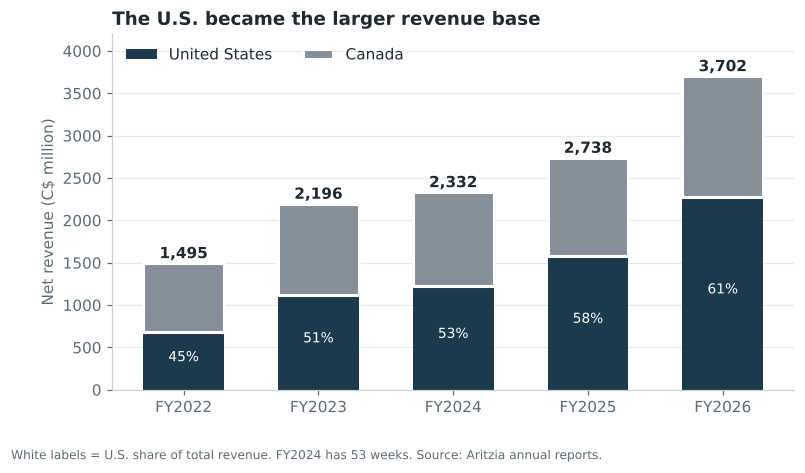

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(a))
ax.bar(x, a['U.S. Revenue'], width=0.6, color=NAVY, label='United States')
ax.bar(x, a['Canada Revenue'], width=0.6, bottom=a['U.S. Revenue'] + 0, color=GREY, label='Canada',
       edgecolor='white', linewidth=2)
for i, r in a.iterrows():
    ax.text(i, r['Net Revenue'] + 60, f"{r['Net Revenue']:,.0f}", ha='center', fontweight='bold', color=INK)
    ax.text(i, r['U.S. Revenue'] / 2, f"{r['U.S. Revenue Mix']:.0%}", ha='center', color='white', fontsize=9)
ax.set_xticks(x, a['Fiscal Year']); ax.set_ylabel('Net revenue (C$ million)')
ax.set_ylim(0, 4200); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, ncol=2, loc='upper left')
ax.set_title('The U.S. became the larger revenue base')
fig.text(0.01, -0.04, 'White labels = U.S. share of total revenue. FY2024 has 53 weeks. Source: Aritzia annual reports.', color=MUTED, fontsize=8)
fig.savefig(IMG / '01_us_canada_revenue.png'); plt.show()

## 3. Does growth convert into profitability?
Annual margins use the originally reported EBITDA definition. The H1 comparison uses the FY2027 definition for both years, and gross margin excludes the FY2027 Q2 tariff refund.

In [6]:
a[['Fiscal Year', 'Gross Margin', 'SG&A % of Revenue', 'Adj. EBITDA Margin', 'Net Income Margin']].set_index('Fiscal Year').style.format('{:.1%}')

,Gross Margin,SG&A % of Revenue,Adj. EBITDA Margin,Net Income Margin
Fiscal Year,,,,
FY2022,43.8%,26.3%,19.4%,10.5%
FY2023,41.6%,27.4%,16.0%,8.5%
FY2024,38.5%,30.4%,9.3%,3.4%
FY2025,43.1%,30.6%,14.8%,7.6%
FY2026,44.9%,29.1%,17.5%,10.3%


In [7]:
fy26 = a.set_index('Fiscal Year').loc['FY2026']
print(f"FY2026 Adj. EBITDA increase {fy26['Adj. EBITDA Increase']:.1f} = revenue scale {fy26['EBITDA Change: Revenue Scale']:.1f}"
      f" + margin change {fy26['EBITDA Change: Margin']:.1f}")
q27q2 = q.set_index('Period').loc['FY2027-Q2']
print(f"FY2027 Q2 gross margin: reported {q27q2['Gross Margin (Reported)']:.1%}, excluding tariff refund {q27q2['Gross Margin excl. Refund']:.1%}")

FY2026 Adj. EBITDA increase 239.9 = revenue scale 143.1 + margin change 96.8
FY2027 Q2 gross margin: reported 57.1%, excluding tariff refund 48.7%


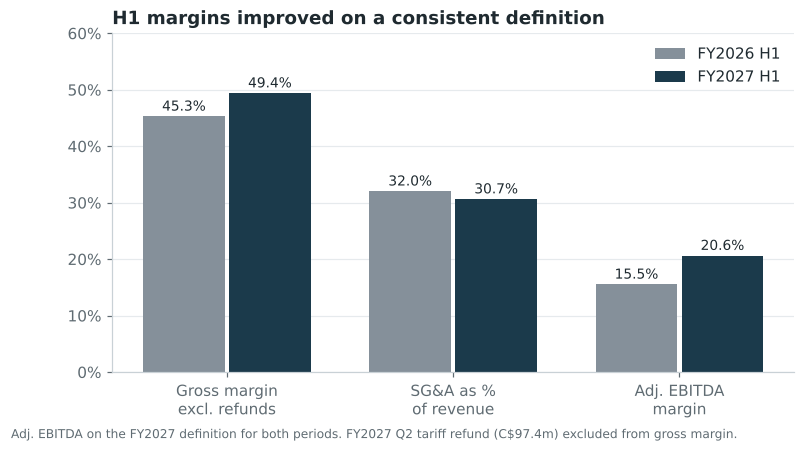

In [8]:
m = h1.set_index('Period').loc[['FY2026 H1', 'FY2027 H1'], ['Gross Margin excl. Refund', 'SG&A % of Revenue', 'Adj. EBITDA Margin']]
labels = ['Gross margin\nexcl. refunds', 'SG&A as %\nof revenue', 'Adj. EBITDA\nmargin']
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3); w = 0.36
for j, (per, color) in enumerate([('FY2026 H1', GREY), ('FY2027 H1', NAVY)]):
    bars = ax.bar(x + (j - 0.5) * (w + 0.02), m.loc[per], width=w, color=color, label=per)
    for b, v in zip(bars, m.loc[per]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.1%}', ha='center', fontsize=9, color=INK)
ax.set_xticks(x, labels); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 0.6); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper right')
ax.set_title('H1 margins improved on a consistent definition')
fig.text(0.01, -0.04, 'Adj. EBITDA on the FY2027 definition for both periods. FY2027 Q2 tariff refund (C$97.4m) excluded from gross margin.', color=MUTED, fontsize=8)
fig.savefig(IMG / '02_h1_margins.png'); plt.show()

## 4. Cash generation and inventory

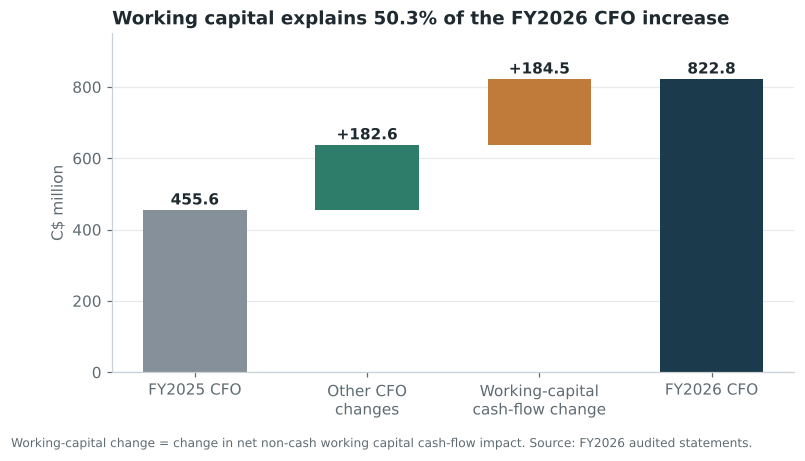

FY2026 FCF excl. WC effects: 298.4
FY2027 H1 FCF 205.7; excluding gross tariff receipt 108.3


In [9]:
fy25, fy26 = a.set_index('Fiscal Year').loc['FY2025'], a.set_index('Fiscal Year').loc['FY2026']
wc_chg = fy26['WC Cash-Flow Impact'] - fy25['WC Cash-Flow Impact']
cfo_chg = fy26['Operating Cash Flow'] - fy25['Operating Cash Flow']
steps = [('FY2025 CFO', fy25['Operating Cash Flow'], 'total'), ('Other CFO\nchanges', cfo_chg - wc_chg, 'chg'),
         ('Working-capital\ncash-flow change', wc_chg, 'chg'), ('FY2026 CFO', fy26['Operating Cash Flow'], 'total')]
fig, ax = plt.subplots(figsize=(8, 4))
run = 0
for i, (lab, v, kind) in enumerate(steps):
    base = 0 if kind == 'total' else run
    color = NAVY if i == 3 else (GREY if i == 0 else (COPPER if i == 2 else TEAL))
    ax.bar(i, v, bottom=base, width=0.6, color=color)
    ax.text(i, base + v + 15, (f'+{v:,.1f}' if kind == 'chg' else f'{v:,.1f}'), ha='center', fontweight='bold', color=INK)
    run = v if kind == 'total' else run + v
ax.set_xticks(range(4), [s[0] for s in steps]); ax.set_ylabel('C$ million'); ax.set_ylim(0, 950); ax.grid(axis='x', visible=False)
ax.set_title(f'Working capital explains {wc_chg / cfo_chg:.1%} of the FY2026 CFO increase')
fig.text(0.01, -0.06, 'Working-capital change = change in net non-cash working capital cash-flow impact. Source: FY2026 audited statements.', color=MUTED, fontsize=8)
fig.savefig(IMG / '03_cfo_bridge.png'); plt.show()
print(f"FY2026 FCF excl. WC effects: {fy26['FCF excl. WC']:.1f}")
r27 = h1.set_index('Period').loc['FY2027 H1']
print(f"FY2027 H1 FCF {r27['Free Cash Flow']:.1f}; excluding gross tariff receipt {r27['FCF excl. Tariff Receipt']:.1f}")

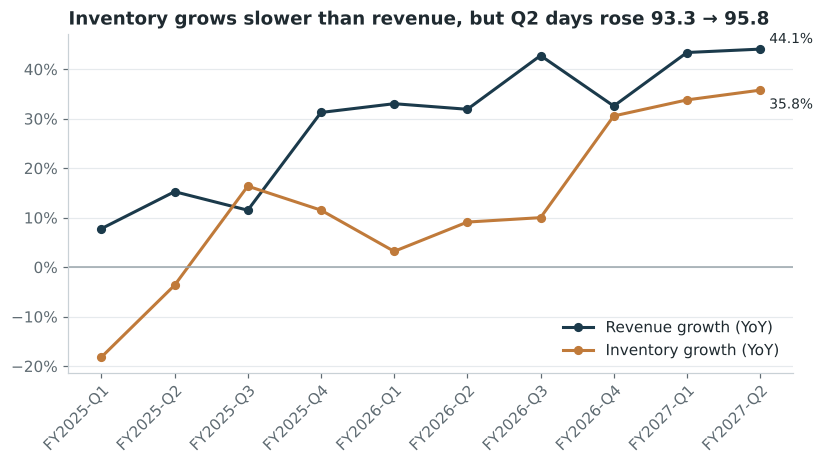

In [10]:
qq = q[q['Fiscal Year'] >= 'FY2025']
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(qq['Period'], qq['Revenue YoY'], color=NAVY, lw=2, marker='o', ms=5, label='Revenue growth (YoY)')
ax.plot(qq['Period'], qq['Inventory YoY'], color=COPPER, lw=2, marker='o', ms=5, label='Inventory growth (YoY)')
ax.axhline(0, color='#9AA5AB', lw=1)
last = qq.iloc[-1]
ax.annotate(f"{last['Revenue YoY']:.1%}", (len(qq) - 1, last['Revenue YoY']), xytext=(6, 4), textcoords='offset points', color=INK, fontsize=9)
ax.annotate(f"{last['Inventory YoY']:.1%}", (len(qq) - 1, last['Inventory YoY']), xytext=(6, -12), textcoords='offset points', color=INK, fontsize=9)
ax.yaxis.set_major_formatter(pct); plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor'); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='lower right')
d26, d27 = q.set_index('Period').loc[['FY2026-Q2', 'FY2027-Q2'], 'Days in Inventory']
ax.set_title(f'Inventory grows slower than revenue, but Q2 days rose {d26:.1f} → {d27:.1f}')
fig.savefig(IMG / '04_inventory_vs_revenue.png'); plt.show()

## 5. What does management guidance require?
FY2027 guidance (8 Oct 2026): revenue C$4,780-4,880m and ~20% Adj. EBITDA margin, excluding tariff refunds.

In [11]:
h2_prior = q[(q['Fiscal Year'] == 'FY2026') & (q['Half'] == 'H2')]['Net Revenue'].sum()
h1_rev, h1_ebitda = r27['Net Revenue'], r27['Adj. EBITDA (Comparable)']
g = pd.DataFrame({'Guidance': [4780, 4830, 4880]}, index=['Low', 'Midpoint', 'High'])
g['H2 revenue required'] = g['Guidance'] - h1_rev
g['H2 growth required'] = g['H2 revenue required'] / h2_prior - 1
g['H2 EBITDA margin required'] = (0.20 * g['Guidance'] - h1_ebitda) / g['H2 revenue required']
g.style.format({'Guidance': '{:,.0f}', 'H2 revenue required': '{:,.1f}', 'H2 growth required': '{:.1%}', 'H2 EBITDA margin required': '{:.1%}'})

,Guidance,H2 revenue required,H2 growth required,H2 EBITDA margin required
Low,"4,780","2,659.2",19.4%,19.5%
Midpoint,"4,830","2,709.2",21.7%,19.5%
High,"4,880","2,759.2",23.9%,19.5%


## 6. Independent scenario forecast
Revenue is built by geography from the same quarter of the prior year (to keep seasonality):

`U.S. revenue = prior-year same-quarter U.S. revenue x (1 + assumed U.S. growth)` (same for Canada)

`Adj. EBITDA = revenue x (gross margin excl. refunds - SG&A ratio + reconciliation ratio)`

The model below is rebuilt independently from `forecast_assumptions.csv` and then reconciled to the Excel model.

In [12]:
def run_forecast(assump, q, dus=0.0, dgm=0.0):
    actual = q.set_index('Period')
    hist = {p: (actual.loc[p, 'U.S. Revenue'], actual.loc[p, 'Canada Revenue']) for p in actual.index}
    rows = []
    for p in ['FY2027-Q1', 'FY2027-Q2']:
        r = actual.loc[p]
        rows.append(dict(Period=p, Status='Actual', us=r['U.S. Revenue'], ca=r['Canada Revenue'],
                         rev=r['Net Revenue'], ebitda=r['Adj. EBITDA (Comparable)'], cogs=r['Net Revenue'] - r['Gross Profit excl. Refund']))
    for _, s in assump.iterrows():
        fy, qtr = s['Period'].split('-')
        prior = f'FY{int(fy[2:]) - 1}-{qtr}'
        pu, pc = hist[prior]
        is28 = fy == 'FY2028'
        us = pu * (1 + s['U.S. Revenue Growth'] + (dus if is28 else 0))
        ca = pc * (1 + s['Canada Revenue Growth'])
        rev = us + ca
        gm = s['Gross Margin excl. Refunds'] + (dgm if is28 else 0)
        rows.append(dict(Period=s['Period'], Status='Forecast', us=us, ca=ca, rev=rev,
                         ebitda=rev * (gm - s['SG&A Ratio'] + s['Reconciliation Ratio']), cogs=rev * (1 - gm)))
        hist[s['Period']] = (us, ca)
    out = pd.DataFrame(rows)
    out['Fiscal Year'] = out['Period'].str[:6]
    return out

INV_DAYS = {'Base': (80, 80), 'Downside': (90, 95), 'Upside': (75, 74)}
results, annual = {}, []
for scen, grp in fa.groupby('Scenario', sort=False):
    f = run_forecast(grp.sort_values('Period'), q)
    results[scen] = f
    opening = a.set_index('Fiscal Year').loc['FY2026', 'Inventory']
    prev_rev = a.set_index('Fiscal Year').loc['FY2026', 'Net Revenue']
    for i, (fy, g_) in enumerate(f.groupby('Fiscal Year')):
        rev, e, cogs = g_['rev'].sum(), g_['ebitda'].sum(), g_['cogs'].sum()
        end_inv = 2 * cogs * INV_DAYS[scen][i] / 364 - opening
        annual.append(dict(Scenario=scen, **{'Fiscal Year': fy}, Revenue=rev, Growth=rev / prev_rev - 1,
                           **{'Adj. EBITDA': e, 'EBITDA Margin': e / rev, 'Ending Inventory': end_inv}))
        opening, prev_rev = end_inv, rev
annual = pd.DataFrame(annual)
annual.style.format({'Revenue': '{:,.1f}', 'Adj. EBITDA': '{:,.1f}', 'Ending Inventory': '{:,.1f}', 'Growth': '{:.1%}', 'EBITDA Margin': '{:.1%}'})

,Scenario,Fiscal Year,Revenue,Growth,Adj. EBITDA,EBITDA Margin,Ending Inventory
0,Base,FY2027,"4,855.8",31.2%,977.5,20.1%,630.9
1,Base,FY2028,"5,598.9",15.3%,"1,140.4",20.4%,662.7
2,Downside,FY2027,"4,667.2",26.1%,902.1,19.3%,732.9
3,Downside,FY2028,"5,056.4",8.3%,920.9,18.2%,689.7
4,Upside,FY2027,"5,044.5",36.3%,"1,045.5",20.7%,595.1
5,Upside,FY2028,"6,124.0",21.4%,"1,292.9",21.1%,702.8


In [13]:
# Reconcile the pandas rebuild to the Excel model (Forecast_Annual sheet)
xl = fy_xl[fy_xl['Fiscal Year'] != 'FY2026'].set_index(['Scenario', 'Fiscal Year'])
py = annual.set_index(['Scenario', 'Fiscal Year'])
diff = pd.DataFrame({'Revenue': (py['Revenue'] - xl['Net Revenue']).abs(),
                     'Adj. EBITDA': (py['Adj. EBITDA'] - xl['Adj. EBITDA']).abs(),
                     'Ending Inventory': (py['Ending Inventory'] - xl['Ending Inventory Target']).abs()})
assert (diff < 1e-3).all().all(), diff
print('Python rebuild matches the Excel model for all scenarios (max abs difference %.2e)' % diff.max().max())

Python rebuild matches the Excel model for all scenarios (max abs difference 4.23e-07)


<>:15: SyntaxWarning: invalid escape sequence '\$'
<>:15: SyntaxWarning: invalid escape sequence '\$'
<>:15: SyntaxWarning: invalid escape sequence '\$'
<>:15: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_383/1308882916.py:15: SyntaxWarning: invalid escape sequence '\$'
  ax.set_title(f"Base case: FY2027 C\${b.loc[('Base','FY2027'),'Revenue']:,.0f}m, FY2028 C\${b.loc[('Base','FY2028'),'Revenue']:,.0f}m revenue")
/tmp/ipykernel_383/1308882916.py:15: SyntaxWarning: invalid escape sequence '\$'
  ax.set_title(f"Base case: FY2027 C\${b.loc[('Base','FY2027'),'Revenue']:,.0f}m, FY2028 C\${b.loc[('Base','FY2028'),'Revenue']:,.0f}m revenue")


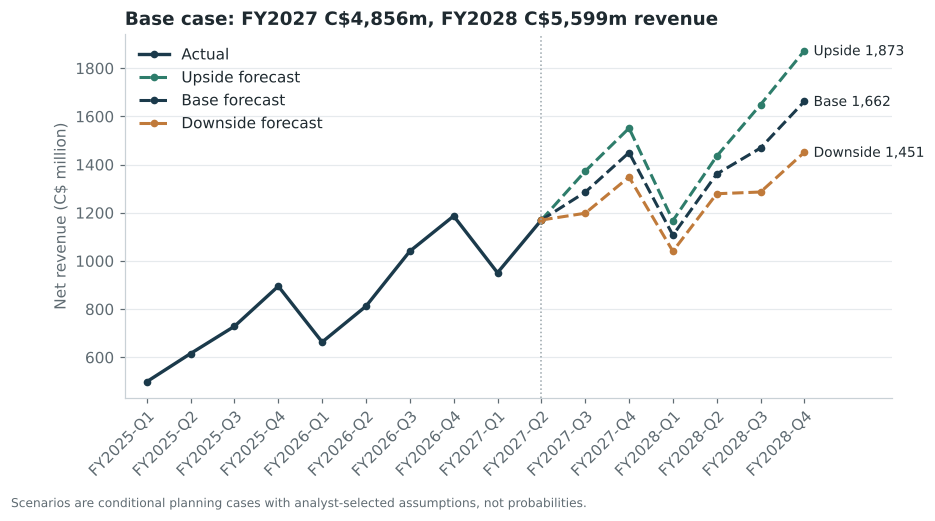

In [14]:
hist = q[q['Fiscal Year'] >= 'FY2025'][['Period', 'Net Revenue']]
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(hist['Period'], hist['Net Revenue'], color=NAVY, lw=2.2, marker='o', ms=4, label='Actual')
styles = {'Upside': TEAL, 'Base': NAVY, 'Downside': COPPER}
for scen, color in styles.items():
    f = results[scen]
    seg = pd.concat([hist.tail(1).rename(columns={'Net Revenue': 'rev'}), f[f['Status'] == 'Forecast'][['Period', 'rev']]])
    ax.plot(seg['Period'], seg['rev'], color=color, lw=2, ls='--', marker='o', ms=4, label=f'{scen} forecast')
    ax.annotate(f"{scen} {seg['rev'].iloc[-1]:,.0f}", (len(hist) + 5, seg['rev'].iloc[-1]), xytext=(6, -3), textcoords='offset points', color=INK, fontsize=9)
ax.axvline(len(hist) - 1, color='#9AA5AB', lw=1, ls=':')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor'); ax.set_ylabel('Net revenue (C$ million)'); ax.grid(axis='x', visible=False)
ax.set_xlim(-0.5, len(hist) + 7)
ax.legend(frameon=False, loc='upper left')
b = annual.set_index(['Scenario', 'Fiscal Year'])
ax.set_title(f"Base case: FY2027 C\${b.loc[('Base','FY2027'),'Revenue']:,.0f}m, FY2028 C\${b.loc[('Base','FY2028'),'Revenue']:,.0f}m revenue")
fig.text(0.01, -0.12, 'Scenarios are conditional planning cases with analyst-selected assumptions, not probabilities.', color=MUTED, fontsize=8)
fig.savefig(IMG / '05_forecast_scenarios.png'); plt.show()

## 7. Sensitivity and benchmark backtest

In [15]:
base28 = results['Base'].query("`Fiscal Year` == 'FY2028'")['ebitda'].sum()
grid = pd.DataFrame({f'GM {dgm:+.0%}': [run_forecast(fa[fa.Scenario == 'Base'].sort_values('Period'), q, dus, dgm)
                                         .query("`Fiscal Year` == 'FY2028'")['ebitda'].sum() for dus in (-.05, 0, .05)]
                     for dgm in (-.01, 0, .01)}, index=['U.S. growth -5pp', 'U.S. growth +0pp', 'U.S. growth +5pp'])
print(f'Base FY2028 Adj. EBITDA: {base28:,.1f}')
grid.style.format('{:,.1f}').set_caption('FY2028 Adj. EBITDA (C$ million)')

Base FY2028 Adj. EBITDA: 1,140.4


,GM -1%,GM +0%,GM +1%
U.S. growth -5pp,"1,053.5","1,107.9","1,162.3"
U.S. growth +0pp,"1,084.4","1,140.4","1,196.4"
U.S. growth +5pp,"1,115.3","1,172.9","1,230.5"


In [16]:
qi = q.set_index('Period')
per = list(qi.index)
bt = []
for p in ['FY2026-Q1', 'FY2026-Q2', 'FY2026-Q3', 'FY2026-Q4', 'FY2027-Q1', 'FY2027-Q2']:
    i = per.index(p); ly, prev = per[i - 4], per[i - 1]
    actual = qi.loc[p, 'Net Revenue']
    naive = qi.loc[ly, 'Net Revenue']
    geo = qi.loc[ly, 'U.S. Revenue'] * (1 + qi.loc[prev, 'U.S. Revenue YoY']) + qi.loc[ly, 'Canada Revenue'] * (1 + qi.loc[prev, 'Canada Revenue YoY'])
    bt.append(dict(Period=p, Actual=actual, Naive=naive, Geo=geo))
bt = pd.DataFrame(bt)
summary = pd.DataFrame({m: {'MAPE': ((bt[m] - bt.Actual).abs() / bt.Actual).mean(),
                            'WAPE': (bt[m] - bt.Actual).abs().sum() / bt.Actual.sum(),
                            'Bias': (bt[m] - bt.Actual).sum() / bt.Actual.sum()} for m in ['Naive', 'Geo']}).T
summary.index = ['Prior-year same quarter', 'Latest geographic growth carried forward']
summary.style.format('{:.1%}')

,MAPE,WAPE,Bias
Prior-year same quarter,27.4%,27.6%,-27.6%
Latest geographic growth carried forward,4.3%,4.7%,-1.0%


**Reading the backtest:** carrying forward the latest regional growth rate tracks revenue far better than seasonality alone during rapid expansion. Six observations do not validate the scenario assumptions; the Base case deliberately tapers growth rather than extrapolating the latest quarter.